# Practical Assignment 3: Performance Evaluation of Regression Model

* Name: Yashraj Ghule
* Div: E
* Batch: E1
* Roll no: 316
* PRN: 202401040319

**GITHUB:** https://github.com/Yashraj221B/AIML_TH_LAB/tree/main/C.A/Practical-03-Regression-Model-Performance
 
## Problem Statement

1. Develop regression models for a real world application and evaluate the performance using appropriate metrics.
2. Implement and analyze the performance of Gradient Descent optimization for Linear Regression.

**Part 1** predicts how much a diabetes patient's condition has progressed after one year from 10 basic medical measurements (age, sex, BMI, blood pressure and six blood serum values), using the diabetes dataset of 442 patients that comes with scikit-learn. **Part 2** writes gradient descent from scratch and tests it on the Salary data (salary against years of experience) and on the diabetes data.

## 1. Import libraries

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)

# Part 1: Regression models for disease progression

## 2. Load the data

In [2]:
data = load_diabetes(as_frame=True)
df = data.frame
print(df.shape)
df.head()

(442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
print(df.isnull().sum().sum(), "missing values")
df.describe().round(3)

0 missing values


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000,152.133
std,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,77.093
min,-0.107,-0.045,-0.090,-0.112,-0.127,-0.116,-0.102,-0.076,-0.126,-0.138,25.000
25%,-0.037,-0.045,-0.034,-0.037,-0.034,-0.030,-0.035,-0.039,-0.033,-0.033,87.000
50%,0.005,-0.045,-0.007,-0.006,-0.004,-0.004,-0.007,-0.003,-0.002,-0.001,140.500
75%,0.038,0.051,0.031,0.036,0.028,0.030,0.029,0.034,0.032,0.028,211.500
max,0.111,0.051,0.171,0.132,0.154,0.199,0.181,0.185,0.134,0.136,346.000


The features in this dataset are already mean-centred and scaled by the dataset authors, and the target `target` is a disease progression score (higher means worse). A quick look at the target and at how each feature correlates with it:

s3    -0.395
sex    0.043
s2     0.174
age    0.188
s1     0.212
s6     0.382
s4     0.430
bp     0.441
s5     0.566
bmi    0.586
Name: target, dtype: float64


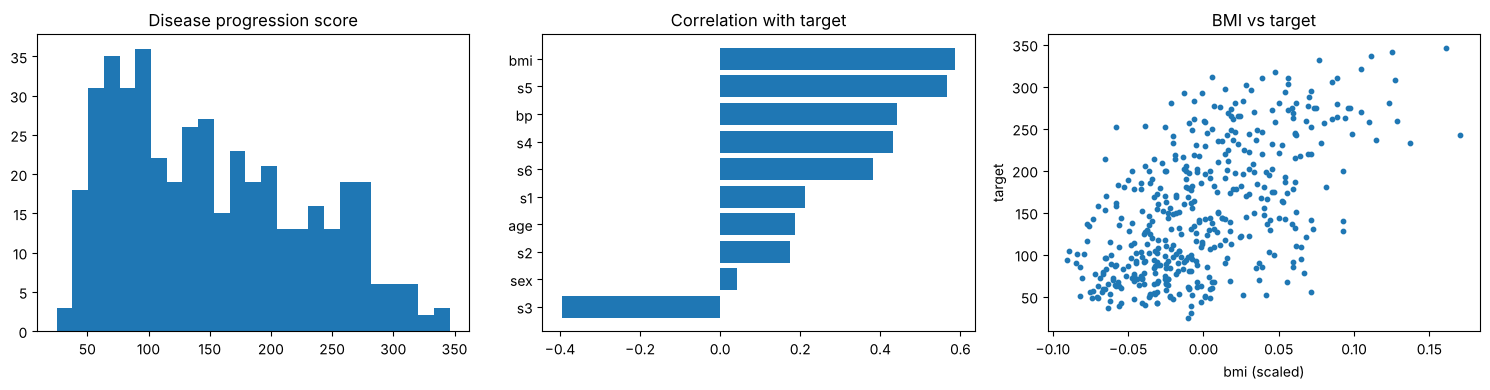

In [4]:
corr = df.corr()["target"].drop("target").sort_values()
print(corr.round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df["target"], bins=25)
ax[0].set_title("Disease progression score")
ax[1].barh(corr.index, corr.values)
ax[1].set_title("Correlation with target")
ax[2].scatter(df["bmi"], df["target"], s=10)
ax[2].set_xlabel("bmi (scaled)")
ax[2].set_ylabel("target")
ax[2].set_title("BMI vs target")
plt.tight_layout()
plt.show()

BMI (0.59), s5 (0.57) and blood pressure (0.44) have the strongest positive correlation with the progression score, and s3 is the only strong negative one (-0.40). The target is a bit right skewed and there are no missing values.

## 3. Train and test split

In [5]:
X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (353, 10) Test: (89, 10)


## 4. Models

* **Linear Regression:** least squares fit, used as the baseline.
* **Polynomial Regression (degree 2):** adds squares and products of the features, so it can fit curves but has many more parameters and can overfit.
* **Ridge Regression:** linear regression with an L2 penalty on the coefficients to reduce overfitting.
* **Lasso Regression:** linear regression with an L1 penalty, which can push some coefficients to exactly zero.

The penalty strengths of Ridge and Lasso are chosen with 5-fold cross validation on the training set only, so the test set is not used for tuning.

Best Ridge alpha: 0.003
Best Lasso alpha: 0.03


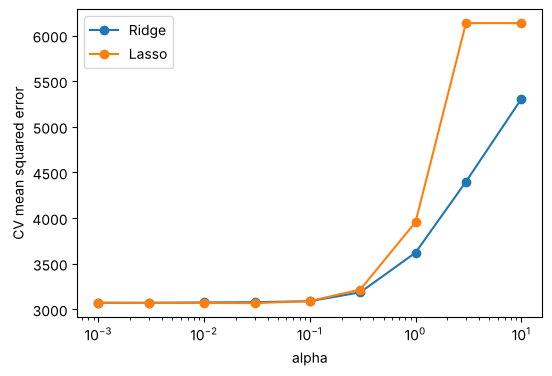

In [6]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def best_alpha(model_class, alphas):
    scores = []
    for a in alphas:
        s = cross_val_score(model_class(alpha=a), X_train, y_train, cv=kf, scoring="neg_mean_squared_error")
        scores.append(-s.mean())
    return alphas[int(np.argmin(scores))], scores

alphas = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]
ridge_alpha, ridge_scores = best_alpha(Ridge, alphas)
lasso_alpha, lasso_scores = best_alpha(Lasso, alphas)
print("Best Ridge alpha:", ridge_alpha)
print("Best Lasso alpha:", lasso_alpha)

plt.figure(figsize=(6, 4))
plt.plot(alphas, ridge_scores, marker="o", label="Ridge")
plt.plot(alphas, lasso_scores, marker="o", label="Lasso")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("CV mean squared error")
plt.legend()
plt.show()

In [7]:
models = {
    "Linear": LinearRegression(),
    "Polynomial (deg 2)": make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression()),
    "Ridge": Ridge(alpha=ridge_alpha),
    "Lasso": Lasso(alpha=lasso_alpha),
}

def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

rows = []
fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    p = model[-1].coef_.shape[0] if hasattr(model, "steps") else len(model.coef_)
    cv_r2 = cross_val_score(model, X_train, y_train, cv=kf, scoring="r2")
    rows.append({
        "Model": name,
        "Train R2": r2_score(y_train, pred_train),
        "Test R2": r2_score(y_test, pred_test),
        "Adj. R2 (test)": adjusted_r2(r2_score(y_test, pred_test), len(y_test), p),
        "MAE": mean_absolute_error(y_test, pred_test),
        "MSE": mean_squared_error(y_test, pred_test),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred_test)),
        "CV R2 (mean)": cv_r2.mean(),
        "CV R2 (std)": cv_r2.std(),
    })

results = pd.DataFrame(rows).set_index("Model")
results.round(3)

,Train R2,Test R2,Adj. R2 (test),MAE,MSE,RMSE,CV R2 (mean),CV R2 (std)
Model,,,,,,,,
Linear,0.528,0.453,0.382,42.794,2900.194,53.853,0.480,0.041
Polynomial (deg 2),0.606,0.416,-1.236,43.582,3096.028,55.642,0.339,0.070
Ridge,0.527,0.454,0.385,42.816,2890.371,53.762,0.481,0.040
Lasso,0.524,0.463,0.394,42.829,2847.707,53.364,0.481,0.038


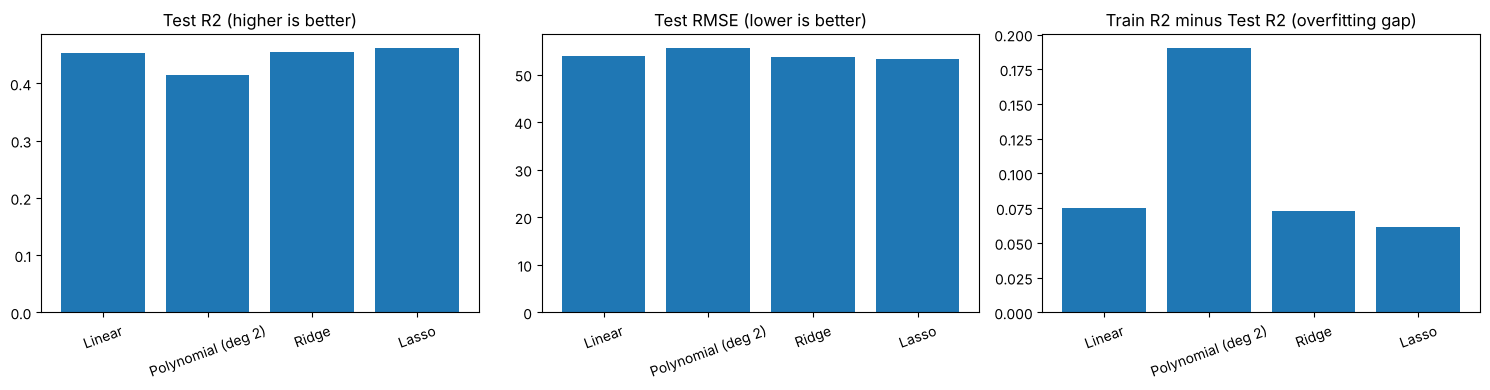

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].bar(results.index, results["Test R2"])
ax[0].set_title("Test R2 (higher is better)")
ax[1].bar(results.index, results["RMSE"])
ax[1].set_title("Test RMSE (lower is better)")
ax[2].bar(results.index, results["Train R2"] - results["Test R2"])
ax[2].set_title("Train R2 minus Test R2 (overfitting gap)")
for a in ax:
    a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

All the linear models are close: test R2 is about 0.45 and RMSE about 54 on a target with a standard deviation of 77, so the features explain a bit under half of the variation. Lasso was slightly best on the test set (R2 0.463, RMSE 53.4), but the difference from Linear (0.453) is small and the 5-fold CV R2 is the same for Ridge and Lasso (0.481 vs 0.480 for Linear), so I would not call it a real win. Polynomial regression got a higher train R2 (0.606) but a lower test R2 (0.416) and a CV R2 of only 0.339, which is overfitting: it has 65 features for 353 training rows, and its adjusted R2 on the test set is negative. So adding complexity did not help here.

## 5. Predicted vs actual and residuals

Plotted for the Linear and Ridge models. The residuals should be spread around zero with no pattern if a linear model is suitable.

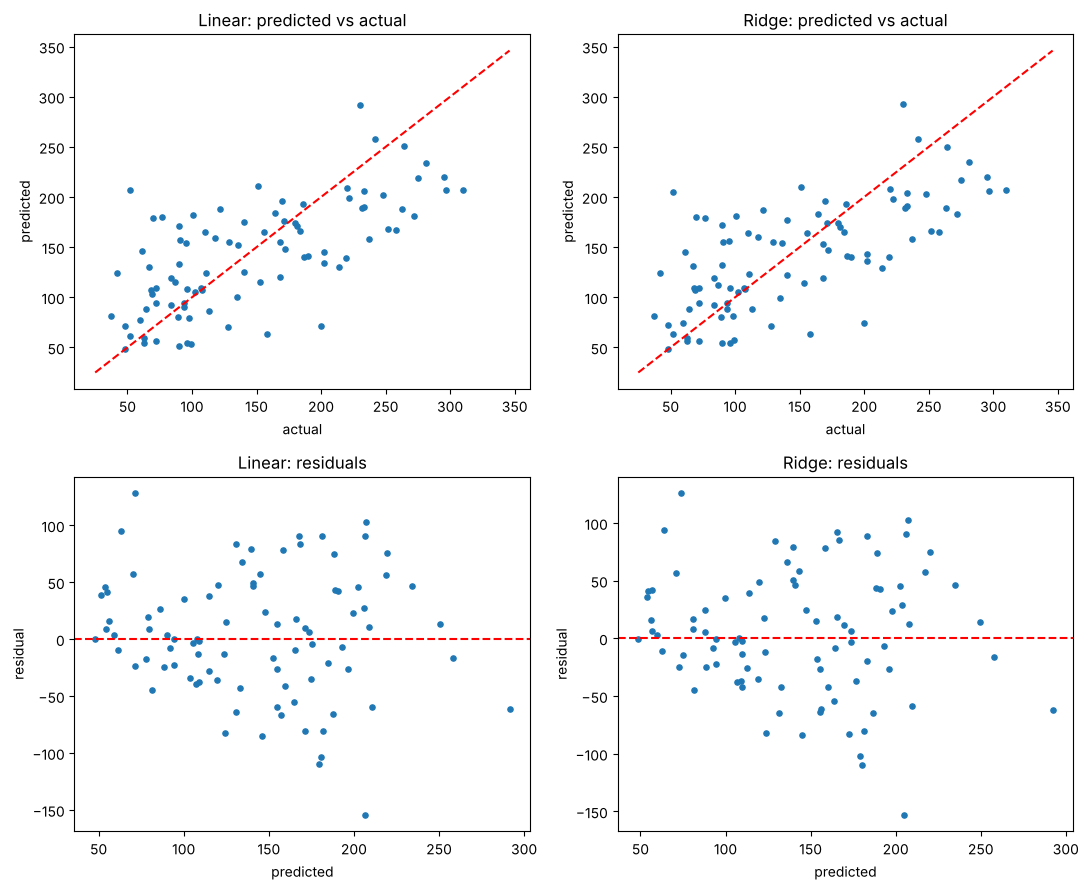

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(11, 9))
for i, name in enumerate(["Linear", "Ridge"]):
    pred = fitted[name].predict(X_test)
    ax[0, i].scatter(y_test, pred, s=14)
    lims = [y.min(), y.max()]
    ax[0, i].plot(lims, lims, "r--")
    ax[0, i].set_title(f"{name}: predicted vs actual")
    ax[0, i].set_xlabel("actual")
    ax[0, i].set_ylabel("predicted")
    ax[1, i].scatter(pred, y_test - pred, s=14)
    ax[1, i].axhline(0, color="r", linestyle="--")
    ax[1, i].set_title(f"{name}: residuals")
    ax[1, i].set_xlabel("predicted")
    ax[1, i].set_ylabel("residual")
plt.tight_layout()
plt.show()

     Linear  Ridge  Lasso
age    37.9   39.3   24.8
sex  -242.0 -240.3 -212.4
bmi   542.4  545.5  555.3
bp    347.7  345.3  331.7
s1   -931.5 -680.0 -226.7
s2    518.1  322.4   -0.0
s3    163.4   50.9 -149.8
s4    275.3  239.9  135.8
s5    736.2  638.9  481.0
s6     48.7   51.5   47.3


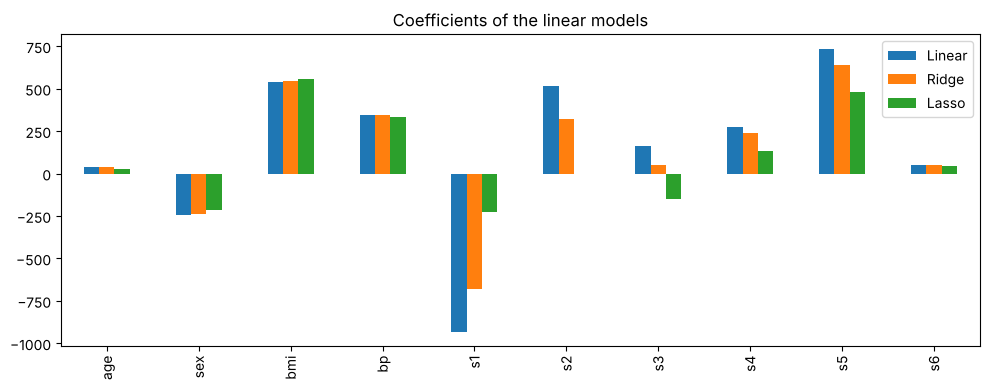

In [10]:
coefs = pd.DataFrame({name: fitted[name].coef_ for name in ["Linear", "Ridge", "Lasso"]}, index=X.columns)
print(coefs.round(1))

coefs.plot(kind="bar", figsize=(10, 4), title="Coefficients of the linear models")
plt.tight_layout()
plt.show()

The residuals have no clear pattern but get wider for large predictions, so the model is weaker for severe cases. In the coefficients, s1 and s2 are two highly correlated serum measurements and have large opposite coefficients in plain Linear Regression. Ridge shrinks them and Lasso sets s2 to exactly 0, which makes the model more stable and easier to read. BMI, blood pressure and s5 stay important in all three.

# Part 2: Gradient Descent for Linear Regression

## 6. The algorithm

For the model ŷ = Xw (a column of ones is added to X for the intercept) the cost is the mean squared error

J(w) = (1 / 2m) Σ (ŷ − y)²

and the gradient is ∇J(w) = (1 / m) Xᵀ(Xw − y). In every iteration the weights move against the gradient: w = w − α ∇J(w), where α is the learning rate.

Three variants are implemented. **Batch** uses all rows for each update, **Stochastic (SGD)** uses one random row, and **Mini-batch** uses a small random group of rows.

In [11]:
def add_bias(X):
    return np.c_[np.ones(len(X)), X]

def cost(Xb, y, w):
    err = Xb @ w - y
    return (err @ err) / (2 * len(y))

def gradient_descent(X, y, lr=0.1, epochs=200, batch_size=None, seed=0, w0=None):
    # batch_size=None -> batch GD, 1 -> SGD, other -> mini-batch
    rng = np.random.default_rng(seed)
    Xb = add_bias(X)
    m = len(y)
    w = np.zeros(Xb.shape[1]) if w0 is None else w0.copy()
    bs = m if batch_size is None else batch_size
    history = [cost(Xb, y, w)]
    path = [w.copy()]
    for epoch in range(epochs):
        idx = rng.permutation(m)
        for start in range(0, m, bs):
            batch = idx[start:start + bs]
            grad = Xb[batch].T @ (Xb[batch] @ w - y[batch]) / len(batch)
            w = w - lr * grad
            path.append(w.copy())
        history.append(cost(Xb, y, w))
        if not np.isfinite(history[-1]):
            break
    return w, history, np.array(path)

def closed_form(X, y):
    Xb = add_bias(X)
    return np.linalg.solve(Xb.T @ Xb, Xb.T @ y)     # normal equation

## 7. Simple linear regression on the Salary data

First a single feature (years of experience) so that everything can be drawn. The feature is standardised, because gradient descent is slow and can fail on features with a large scale.

In [ ]:
sal = pd.read_csv("data/Salary_Data.csv")
print(sal.shape)
print(sal.head())

Xs = sal[["YearsExperience"]].values
ys = sal["Salary"].values
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.2, random_state=42)

sc = StandardScaler().fit(Xs_tr)
A_tr, A_te = sc.transform(Xs_tr), sc.transform(Xs_te)
# salary is also scaled so the learning rates are easy to compare
y_mu, y_sd = ys_tr.mean(), ys_tr.std()
b_tr = (ys_tr - y_mu) / y_sd

w_cf = closed_form(A_tr, b_tr)
w_gd, hist_gd, path_gd = gradient_descent(A_tr, b_tr, lr=0.1, epochs=100)
print("Normal equation weights:", w_cf.round(5))
print("Gradient descent weights:", w_gd.round(5))
print("Final cost GD:", round(hist_gd[-1], 6), "| cost at the exact solution:", round(cost(add_bias(A_tr), b_tr, w_cf), 6))

(30, 2)
   YearsExperience  Salary
0              1.1   39343
1              1.3   46205
2              1.5   37731
3              2.0   43525
4              2.2   39891
Normal equation weights: [0.      0.98211]
Gradient descent weights: [-0.       0.98208]
Final cost GD: 0.01773 | cost at the exact solution: 0.01773


Test R2  GD: 0.9024 | sklearn: 0.9024
Test RMSE GD: 7059.1 | sklearn: 7059.0


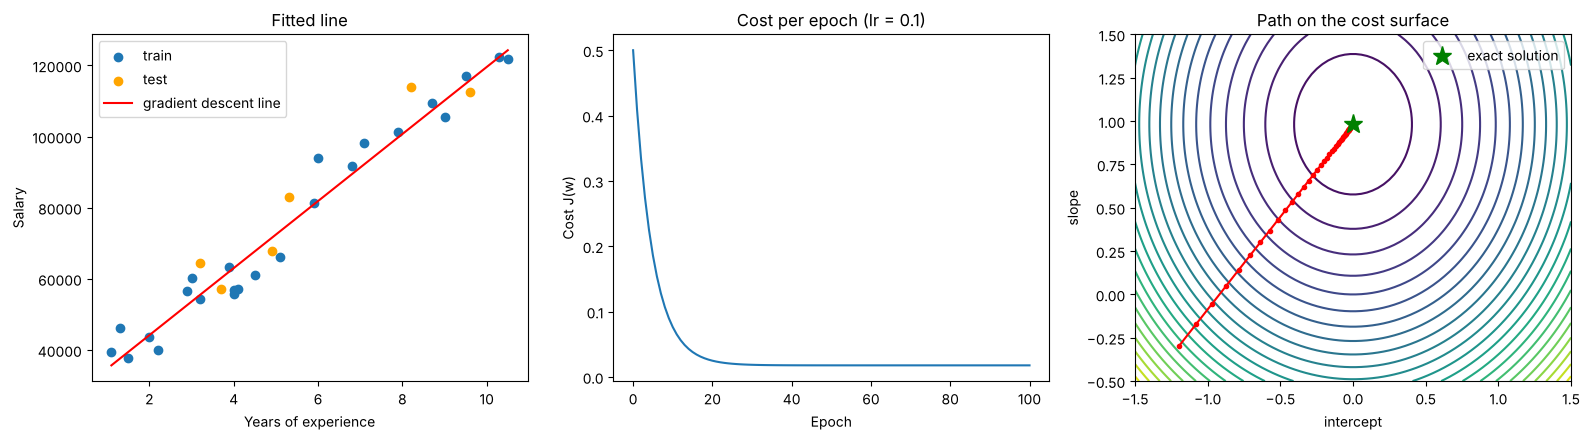

In [13]:
def to_salary(Xnew, w):
    return (add_bias(sc.transform(Xnew)) @ w) * y_sd + y_mu

pred_gd = to_salary(Xs_te, w_gd)
pred_sk = LinearRegression().fit(Xs_tr, ys_tr).predict(Xs_te)
print("Test R2  GD:", round(r2_score(ys_te, pred_gd), 4), "| sklearn:", round(r2_score(ys_te, pred_sk), 4))
print("Test RMSE GD:", round(np.sqrt(mean_squared_error(ys_te, pred_gd)), 1), "| sklearn:", round(np.sqrt(mean_squared_error(ys_te, pred_sk)), 1))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(Xs_tr, ys_tr, label="train")
ax[0].scatter(Xs_te, ys_te, color="orange", label="test")
grid = np.linspace(Xs.min(), Xs.max(), 100).reshape(-1, 1)
ax[0].plot(grid, to_salary(grid, w_gd), "r", label="gradient descent line")
ax[0].set_xlabel("Years of experience")
ax[0].set_ylabel("Salary")
ax[0].legend()
ax[0].set_title("Fitted line")

ax[1].plot(hist_gd)
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Cost J(w)")
ax[1].set_title("Cost per epoch (lr = 0.1)")

# cost surface with the path taken by gradient descent
w0g = np.linspace(-1.5, 1.5, 80)
w1g = np.linspace(-0.5, 1.5, 80)
Z = np.array([[cost(add_bias(A_tr), b_tr, np.array([a, b])) for a in w0g] for b in w1g])
ax[2].contour(w0g, w1g, Z, levels=25)
start_path = gradient_descent(A_tr, b_tr, lr=0.1, epochs=40, w0=np.array([-1.2, -0.3]))[2]
ax[2].plot(start_path[:, 0], start_path[:, 1], "r.-")
ax[2].plot(*w_cf, "g*", markersize=14, label="exact solution")
ax[2].set_xlabel("intercept")
ax[2].set_ylabel("slope")
ax[2].set_title("Path on the cost surface")
ax[2].legend()
plt.tight_layout()
plt.show()

Gradient descent reached the same line as the normal equation (slope 0.98208 against 0.98211 on the scaled data) and the same final cost (0.01773). The test R2 is 0.9024 for both and the RMSE is about 7059, so gradient descent matches sklearn. In the contour plot the path goes straight down towards the minimum.

## 8. Effect of the learning rate

The same problem is run with several learning rates. A very small rate is slow, a good rate converges quickly, and a rate that is too large makes the cost go up (divergence).

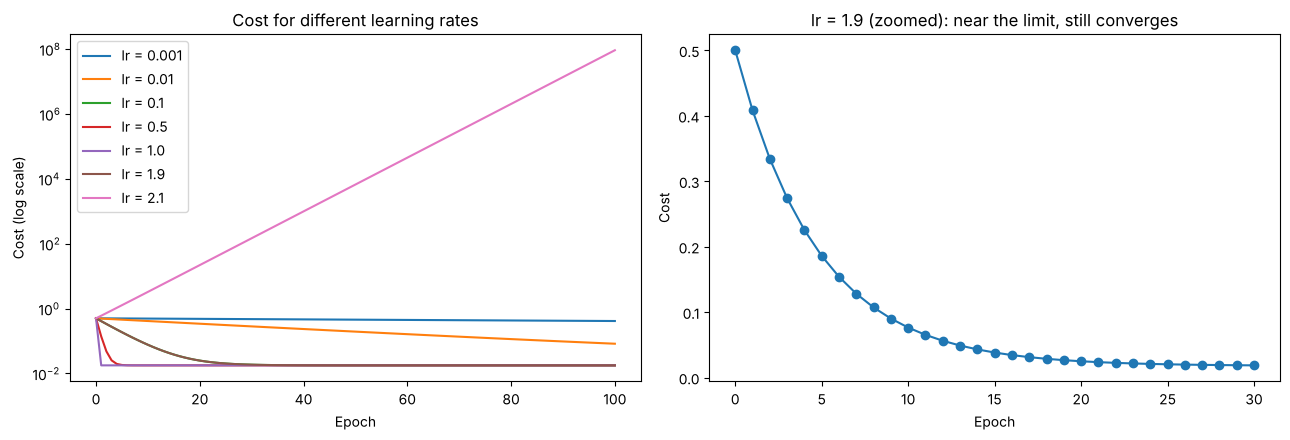

,learning rate,final cost,epochs to reach within 1e-4 of best,diverged
0,0.001,4.125400e-01,not reached,False
1,0.010,8.234400e-02,not reached,False
2,0.100,1.773000e-02,41,False
3,0.500,1.773000e-02,7,False
4,1.000,1.773000e-02,1,False
5,1.900,1.773000e-02,41,False
6,2.100,9.158563e+07,not reached,True


In [14]:
rates = [0.001, 0.01, 0.1, 0.5, 1.0, 1.9, 2.1]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
rows = []
target = cost(add_bias(A_tr), b_tr, w_cf)
for lr in rates:
    w, h, _ = gradient_descent(A_tr, b_tr, lr=lr, epochs=100)
    h = np.array(h)
    ax[0].plot(h, label=f"lr = {lr}")
    close = np.where(h - target < 1e-4)[0]
    rows.append({"learning rate": lr, "final cost": h[-1],
                 "epochs to reach within 1e-4 of best": int(close[0]) if len(close) else "not reached",
                 "diverged": bool(h[-1] > h[0])})
ax[0].set_yscale("log")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Cost (log scale)")
ax[0].set_title("Cost for different learning rates")
ax[0].legend()
ax[1].plot(np.array(gradient_descent(A_tr, b_tr, lr=1.9, epochs=30)[1]), marker="o")
ax[1].set_title("lr = 1.9 (zoomed): near the limit, still converges")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Cost")
plt.tight_layout()
plt.show()
pd.DataFrame(rows).round(6)

A learning rate of 0.001 or 0.01 is too slow: after 100 epochs the cost is still 0.41 and 0.08. A rate of 0.1 needed 41 epochs, 0.5 needed 7 and 1.0 needed 1. At 1.9 it still converges but is slower again, and at 2.1 the cost explodes (about 9e7 after 100 epochs). So the best rate is large but below the limit, and with standardised data the limit is about 2.

## 9. Gradient descent on the diabetes data (10 features)

Batch, SGD and mini-batch gradient descent are compared with the exact least squares solution on the same train and test split as Part 1. The target is standardised for the same reason as above (and so are the features).

In [15]:
# the 10 features have a very small scale (std about 0.05), so they are standardised again for gradient descent
sc_d = StandardScaler().fit(X_train)
Xd_tr, Xd_te = sc_d.transform(X_train), sc_d.transform(X_test)
yd_mu, yd_sd = y_train.mean(), y_train.std()
yd_tr = ((y_train - yd_mu) / yd_sd).values

w_exact = closed_form(Xd_tr, yd_tr)
best_cost = cost(add_bias(Xd_tr), yd_tr, w_exact)

configs = {
    "Batch (lr 0.5)": dict(lr=0.5, epochs=300, batch_size=None),
    "Mini-batch 32 (lr 0.02)": dict(lr=0.02, epochs=300, batch_size=32),
    "SGD (lr 0.002)": dict(lr=0.002, epochs=300, batch_size=1),
}
runs = {}
rows = []
for name, cfg in configs.items():
    t0 = time.perf_counter()
    w, h, _ = gradient_descent(Xd_tr, yd_tr, **cfg)
    t = (time.perf_counter() - t0) * 1000
    pred = add_bias(Xd_te) @ w * yd_sd + yd_mu
    runs[name] = h
    rows.append({"Method": name, "Final train cost": h[-1],
                 "Test R2": r2_score(y_test, pred),
                 "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                 "Max weight difference from exact": np.abs(w - w_exact).max(),
                 "Time (ms)": t})

pred_exact = add_bias(Xd_te) @ w_exact * yd_sd + yd_mu
rows.append({"Method": "Normal equation", "Final train cost": best_cost,
             "Test R2": r2_score(y_test, pred_exact),
             "Test RMSE": np.sqrt(mean_squared_error(y_test, pred_exact)),
             "Max weight difference from exact": 0.0, "Time (ms)": np.nan})
gd_table = pd.DataFrame(rows).set_index("Method")
gd_table.round(4)

,Final train cost,Test R2,Test RMSE,Max weight difference from exact,Time (ms)
Method,,,,,
Batch (lr 0.5),0.2355,0.4541,53.7809,0.1320,15.2245
Mini-batch 32 (lr 0.02),0.2385,0.4407,54.4372,0.2507,55.6778
SGD (lr 0.002),0.2356,0.4555,53.7104,0.0792,738.2542
Normal equation,0.2354,0.4526,53.8534,0.0000,NaN


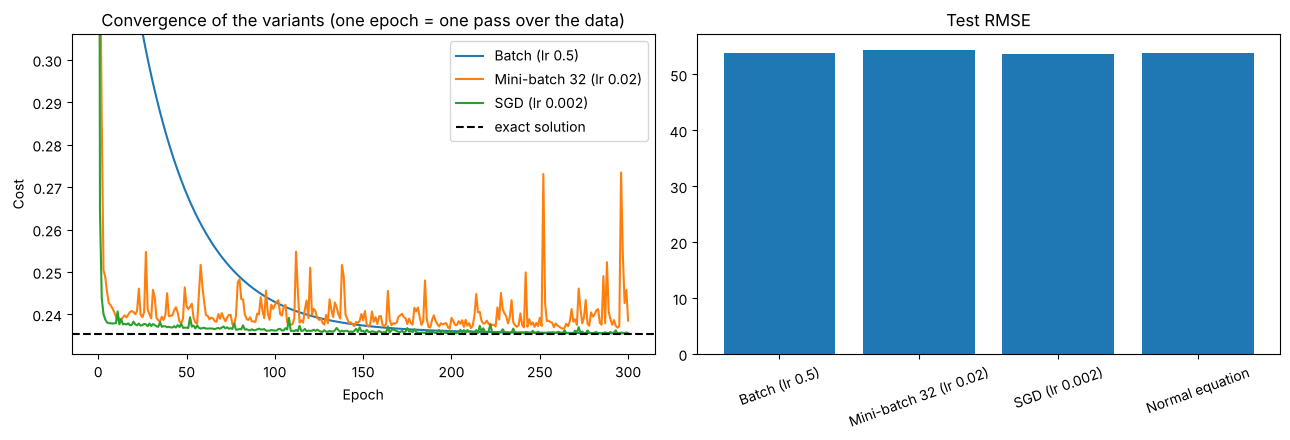

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, h in runs.items():
    ax[0].plot(h, label=name)
ax[0].axhline(best_cost, color="k", linestyle="--", label="exact solution")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Cost")
ax[0].set_ylim(best_cost * 0.98, best_cost * 1.3)
ax[0].set_title("Convergence of the variants (one epoch = one pass over the data)")
ax[0].legend()

ax[1].bar(gd_table.index, gd_table["Test RMSE"])
ax[1].set_title("Test RMSE")
ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

With standardised features all three variants end at almost the same cost as the exact solution (0.2354) and give the same test R2 (about 0.44 to 0.46) and RMSE (about 54). Batch GD is smooth and the fastest in time (11 ms for 300 epochs) but it is slow along the direction of the correlated features s1 and s2, so its weights are still 0.13 away from the exact ones. SGD ends closest to the exact cost and its curve is noisy but it took about 750 ms because it makes one update per row (353 per epoch). Mini-batch is a middle option (41 ms) but with the rate used it is noisier at the end (cost 0.2385). For a small dataset like this the normal equation is simplest, and gradient descent becomes useful when there are very many rows or features.

## 10. Why feature scaling matters

The Salary data is run again without standardising the years of experience and the salary (raw units), with the same learning rate that worked before.

In [17]:
Xraw = Xs_tr
yraw = ys_tr.astype(float)
for lr in [0.1, 0.01, 0.001]:
    w, h, _ = gradient_descent(Xraw, yraw, lr=lr, epochs=200)
    verdict = "diverged" if (not np.isfinite(h[-1]) or h[-1] > h[0]) else "decreasing but far from the best cost"
    print(f"lr = {lr}: start cost = {h[0]:.4g}, final cost = {h[-1]:.4g} ({verdict})")

# a rate that works on the raw data is tiny, and it still has not converged after many epochs
w, h, _ = gradient_descent(Xraw, yraw, lr=0.001, epochs=5000)
print("lr = 0.001, 5000 epochs ->", w.round(1), "| exact:", closed_form(Xraw, yraw).round(1))

lr = 0.1: start cost = 3.136e+09, final cost = 2.211e+175 (diverged)
lr = 0.01: start cost = 3.136e+09, final cost = 3.92e+07 (decreasing but far from the best cost)
lr = 0.001: start cost = 3.136e+09, final cost = 7.246e+07 (decreasing but far from the best cost)
lr = 0.001, 5000 epochs -> [17936.6 10519. ] | exact: [25321.6  9423.8]


Without scaling the same method fails. With raw salary values lr = 0.1 diverges (cost 2e175), and lr = 0.01 or 0.001 do not diverge but are still far from the best cost. Even after 5000 epochs with lr = 0.001 the intercept is 17,937 against the exact 25,322. So feature scaling is needed, because the slope and intercept directions have very different curvature and only a tiny learning rate is stable.

## 11. Sanity checks

In [18]:
# gradient descent should end close to the exact least squares answer
assert np.abs(w_gd - w_cf).max() < 1e-3, "GD far from exact solution"
assert np.abs(gradient_descent(Xd_tr, yd_tr, lr=0.5, epochs=2000)[0] - w_exact).max() < 1e-3
# analytic gradient equals a numerical gradient
Xb = add_bias(Xd_tr)
w_try = np.random.default_rng(1).normal(size=Xb.shape[1])
analytic = Xb.T @ (Xb @ w_try - yd_tr) / len(yd_tr)
numeric = np.array([(cost(Xb, yd_tr, w_try + 1e-6 * e) - cost(Xb, yd_tr, w_try - 1e-6 * e)) / 2e-6 for e in np.eye(len(w_try))])
assert np.allclose(analytic, numeric, atol=1e-6)
print("All checks passed.")

All checks passed.


# 12. Conclusion

**Part 1.** The diabetes progression can be predicted only moderately with a linear model: test R2 about 0.45 and RMSE about 54 (MAE about 43). Ridge and Lasso were slightly better than plain Linear Regression and are easier to trust because they control the effect of the correlated serum features, and Lasso also selects features. Polynomial regression overfit, so the simple model is the right choice for 442 patients. The metrics used were R2, adjusted R2, MAE, MSE and RMSE and 5-fold cross validation, and the penalties were tuned on the training data only.

**Part 2.** Gradient descent written from scratch matches the exact least squares solution on both datasets. The learning rate decides everything (too small is slow, too large diverges), feature scaling is necessary, and batch, mini-batch and SGD trade stability against cost per update.

**Ethics and limits.** This model should not be used to make medical decisions: an R2 of 0.45 means large errors for individual patients, the data has only 442 patients from one study, and `sex` and `age` are used as inputs, which can lead to unfair treatment if they are misused. Future work: try other regression models, check for outliers, test on a bigger dataset and try learning rate schedules and momentum for gradient descent.